# Predicting Student Depression from Lifestyle and Academic Factors

University students today face increasing academic pressure, financial stress, social expectations, and uncertainty about their future. Over the last decade, mental health issues among students have become a growing concern worldwide, with depression being one of the most common and impactful conditions. Depression does not only affect academic performance, but also quality of life, relationships, and long-term well-being.
I personally find this topic important for two reasons. First, as a university student, I see how common stress, burnout, and emotional struggles are in academic environments. Second, I believe that data analysis and machine learning can help identify patterns that are not immediately visible, allowing institutions to better understand which factors are most strongly associated with depression and potentially design more targeted prevention strategies.
For these reasons, this project investigates whether lifestyle, academic, and personal variables can be used to predict depression among students, and which factors appear to be the most strongly associated with it.

**Research Question:** *Which lifestyle, academic, and personal factors are most strongly associated with depression in university students?*

Dataset Source: https://www.kaggle.com/datasets/hopesb/student-depression-dataset

The dataset contains 27,901 observations and 18 columns covering academic pressure, study habits, sleep patterns, dietary habits, financial stress, and family background. The target variable is `Depression` (binary: 0 = not depressed, 1 = depressed).

The project follows a structured machine learning pipeline: missing value analysis, data transformation through a `ColumnTransformer`, nested cross-validation for model selection, model refinement, bias-variance analysis, and feature importance evaluation.

In [ ]:
!pip install missingno==0.5.2

In [ ]:
!pip install xgboost==3.2.0

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import (learning_curve, validation_curve, train_test_split,
                                     RandomizedSearchCV, cross_validate,
                                     RepeatedStratifiedKFold)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance
from scipy.stats import uniform, randint, loguniform

## 1. Exploratory Data Analysis and Initial Data Cleaning

In [ ]:
df = pd.read_csv('/Student Depression Dataset.csv')
df.shape

(27901, 18)

In [ ]:
df.head()

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [ ]:
df.dtypes

,0
id,int64
Gender,object
Age,float64
City,object
Profession,object
Academic Pressure,float64
Work Pressure,float64
CGPA,float64
Study Satisfaction,float64
Job Satisfaction,float64


In [ ]:
print(f"Dataset: {df.shape}")


Dataset: (27901, 18)


While inspecting the categorical variables, I noticed that some entries in *Sleep Duration* and *Dietary Habits* contain the value `"Others"`.
To better understand the situation, I first printed the unique values and counted how many times `"Others"` appears.

In [ ]:
print("Unique values in Sleep Duration:")
print(df["Sleep Duration"].unique())

print("\nUnique values in Dietary Habits:")
print(df["Dietary Habits"].unique())

print(f"\n'Others' values found:")
print(f"  Sleep Duration:  {(df['Sleep Duration'] == 'Others').sum()} ({(df['Sleep Duration'] == 'Others').sum()/len(df)*100:.2f}%)")
print(f"  Dietary Habits:  {(df['Dietary Habits'] == 'Others').sum()} ({(df['Dietary Habits'] == 'Others').sum()/len(df)*100:.2f}%)")

df = df[df['Sleep Duration'] != 'Others']
df = df[df['Dietary Habits'] != 'Others']

print(f"\nAfter removal: {df.shape}")
n_removed = 27901 - df.shape[0]
print(f"Removed: {n_removed} samples ({n_removed/27901*100:.2f}%) — negligible impact")

Unique values in Sleep Duration:
['5-6 hours' 'Less than 5 hours' '7-8 hours' 'More than 8 hours' 'Others']

Unique values in Dietary Habits:
['Healthy' 'Moderate' 'Unhealthy' 'Others']

'Others' values found:
  Sleep Duration:  18 (0.06%)
  Dietary Habits:  12 (0.04%)

After removal: (27871, 18)
Removed: 30 samples (0.11%) — negligible impact


From this inspection, I observed that:
`"Others"` appears 18 times in *Sleep Duration*.
`"Others"` appears 12 times in *Dietary Habits*.
In total, these represent 30 observations out of 27,901 (~0.11% of the dataset).
The label `"Others"` does not provide clear or interpretable information and cannot be consistently placed within the natural ordinal order of these two features.
Since these observations represent a negligible percentage of the dataset and do not carry meaningful structured information, I decided to remove them to preserve clean and interpretable categorical encodings.

## 2. Missing Values Analysis

I check for missing values across all columns to identify features that might need imputation or removal.

In [ ]:
df.isnull().sum(axis=0) / df.shape[0]

,0
id,0.000000
Gender,0.000000
Age,0.000000
City,0.000000
Profession,0.000000
Academic Pressure,0.000000
Work Pressure,0.000000
CGPA,0.000000
Study Satisfaction,0.000000
Job Satisfaction,0.000000


I use `missingno` to visualize where missing values are located.

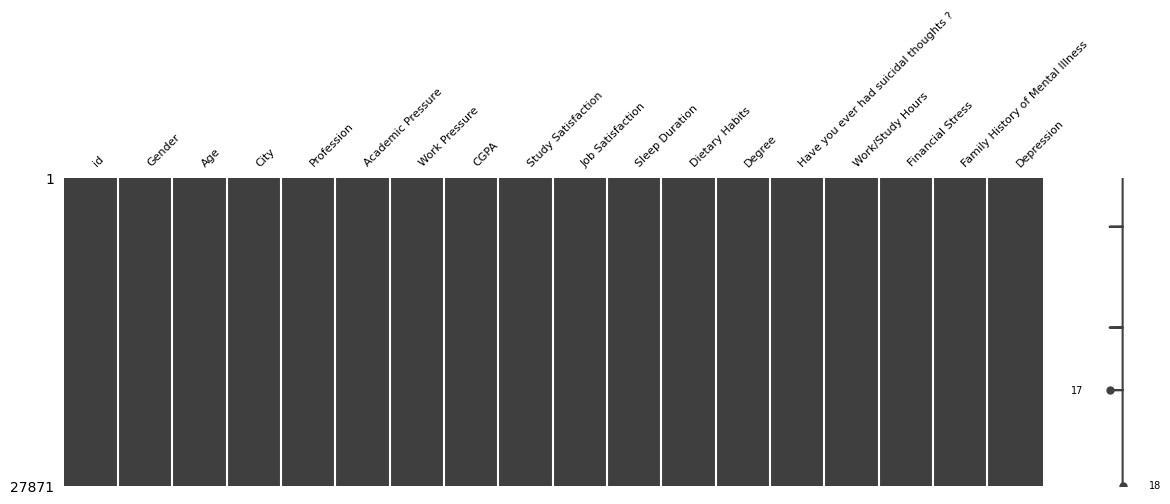

In [ ]:
msno.matrix(df, figsize=(14, 4), fontsize=8)
plt.tight_layout()
plt.show()

Only **Financial Stress** has 3 missing values out of 27,871 (< 0.01%). I handle this in the preprocessing pipeline with `SimpleImputer(strategy='mean')`.

No columns need to be dropped due to missing values.

I inspect features to identify those that should be discarded due to low variance or irrelevance.

In [ ]:
# Check for constant or near-constant features
for col in df.columns:
    top_freq = df[col].value_counts(normalize=True).iloc[0]
    if top_freq > 0.95:
        print(f'{col:40s} \u2192 top value covers {top_freq*100:.1f}%')

Profession                               → top value covers 99.9%
Work Pressure                            → top value covers 100.0%
Job Satisfaction                         → top value covers 100.0%


I drop the following columns:

- **id**: unique identifier, no predictive value.
- **Profession**: 99.9% are "Student" — effectively constant.
- **Work Pressure**: 100% zeros — constant.
- **Job Satisfaction**: 100% zeros — constant.
- **City**: 52 unique values; too many one-hot columns for little gain.
- **Degree**: 28 unique categories; same problem as City.

I keep **Gender** in the dataset and let the model decide if it carries predictive value. The feature importance analysis (Section 8) will confirm this.

In [ ]:
drop_cols = ['id', 'City', 'Profession', 'Work Pressure', 'Job Satisfaction', 'Degree']

df = df.drop(columns=drop_cols)
print(f'Shape after dropping: {df.shape}')
print(f'Remaining columns: {list(df.columns)}')

Shape after dropping: (27871, 12)
Remaining columns: ['Gender', 'Age', 'Academic Pressure', 'CGPA', 'Study Satisfaction', 'Sleep Duration', 'Dietary Habits', 'Have you ever had suicidal thoughts ?', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Depression']


I verify the target distribution.

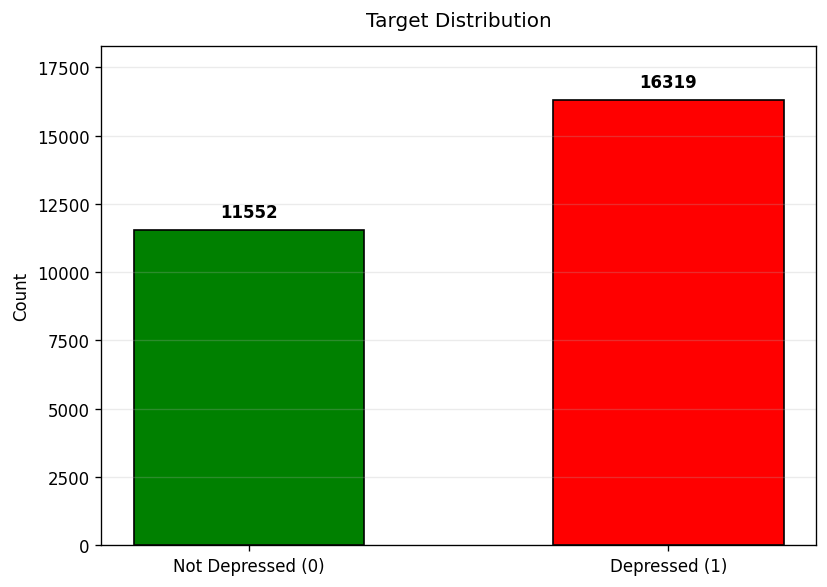

Depressed: 16319 (58.6%)
Not depressed: 11552 (41.4%)


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5), dpi=120)

counts = df["Depression"].value_counts().sort_index()
labels = ["Not Depressed (0)", "Depressed (1)"]

bars = ax.bar(labels, counts.values, edgecolor="black", width=0.55, color=["green", "red"])

ax.set_ylabel("Count")
ax.set_title("Target Distribution", pad=12)

ymax = counts.max()
ax.set_ylim(0, ymax * 1.12)

for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h + ymax*0.02, f"{int(h)}",
            ha="center", va="bottom", fontweight="bold", fontsize=10)

ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Depressed: {counts[1]} ({counts[1]/counts.sum()*100:.1f}%)")
print(f"Not depressed: {counts[0]} ({counts[0]/counts.sum()*100:.1f}%)")

The classes are moderately imbalanced (58.6% vs 41.4%, ratio 1.41:1). This level of imbalance is relatively mild and does not justify the use of resampling techniques such as SMOTE. Instead, potential imbalance effects can be handled directly by the models through class weighting, avoiding artificial changes to the original data distribution.

## 3. Definition of the Data Transformation Pipeline

Here I define the transformation pipeline. The remaining 11 features are organized by type:

| Feature | Type | Transformation |
|---|---|---|
| Age, CGPA, Work/Study Hours | Numerical continuous | `SimpleImputer(mean)` \u2192 `StandardScaler` |
| Academic Pressure, Study Satisfaction, Financial Stress | Numerical (Likert 0\u20135) | `SimpleImputer(mean)` \u2192 `StandardScaler` |
| Sleep Duration | Ordinal text (4 ordered categories) | `OrdinalEncoder` \u2192 `StandardScaler` |
| Dietary Habits | Ordinal text (3 ordered categories) | `OrdinalEncoder` \u2192 `StandardScaler` |
| Suicidal thoughts, Family History, Gender | Binary text (Yes/No or Male/Female) | `OrdinalEncoder` |

All numerical and ordinal features are scaled with `StandardScaler` so that Logistic Regression treats all features equally. Tree-based models are invariant to scaling.

With only 11 features, there is no need for dimensionality reduction (PCA/LDA).

### Feature Groups

Sleep Duration and Dietary Habits have a natural ordering (ex. "Less than 5 hours" < "5-6 hours" < "7-8 hours" < "More than 8 hours"), so I encode them as ordinals to preserve this information.

In [ ]:
numerical_features = [
    'Age',
    'CGPA',
    'Work/Study Hours',
    'Academic Pressure',
    'Study Satisfaction',
    'Financial Stress'
]

ordinal_features_config = [
    ('Sleep Duration', ['Less than 5 hours', '5-6 hours', '7-8 hours', 'More than 8 hours']),
    ('Dietary Habits', ['Unhealthy', 'Moderate', 'Healthy'])
]

ordinal_feature_names = [name for name, _ in ordinal_features_config]
ordinal_categories = [cats for _, cats in ordinal_features_config]

binary_features = [
    'Have you ever had suicidal thoughts ?',
    'Family History of Mental Illness',
    'Gender'
]

print("Feature groups:")
print(f"  Numerical: {len(numerical_features)}")
print(f"  Ordinal:   {len(ordinal_feature_names)}")
print(f"  Binary:    {len(binary_features)}")
print(f"  Total:     {len(numerical_features) + len(ordinal_feature_names) + len(binary_features)}")

Feature groups:
  Numerical: 6
  Ordinal:   2
  Binary:    3
  Total:     11


### Column Transformer

I define a pipeline for each feature group. The `ColumnTransformer` applies each pipeline to the corresponding columns and drops everything else.

In [ ]:
# Pipeline for numerical features: impute missing values, then scale
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Pipeline for ordinal features: impute, encode with explicit category order, then scale
ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )),
    ('scaler', StandardScaler())
])

# Pipeline for binary features: impute and encode Yes/No as 0/1
binary_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

# Final ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numerical_pipeline, numerical_features),
        ('ordinal', ordinal_pipeline, ordinal_feature_names),
        ('binary', binary_pipeline, binary_features)
    ],
    remainder='drop'
)

## 4. Training and Test Sets

I split into training (80%) and test (20%) with stratification on the target. The test set will be used **only** at the end of the model selection process.

In [ ]:
X = df.drop(columns=['Depression'])
y = df['Depression'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42, shuffle=True
)

print(f'Training set: {X_train.shape[0]} samples')
print(f'Test set:     {X_test.shape[0]} samples')
print(f'Training class distribution: {y_train.value_counts().to_dict()}')

Training set: 22296 samples
Test set:     5575 samples
Training class distribution: {1: 13055, 0: 9241}


## 5. Model Selection

I use nested cross-validation to identify the best model. The inner loop (`RandomizedSearchCV`) optimizes hyperparameters, while the outer loop (`cross_validate`) gives an unbiased estimate of generalization performance.
It is important to clarify that the test set is strictly held out during this phase. All model selection and hyperparameter tuning are performed exclusively on the training data through nested cross-validation. The test set is accessed only once at the very end of the process to provide an unbiased estimate of the final model’s generalization performance.

### 5.1 Model Pipeline

I define a generic pipeline with a placeholder classifier that will be swapped during the search.

In [ ]:
model_pipeline = Pipeline([
    ('trans', preprocessor),
    ('classifier', LogisticRegression())
])

Sanity check: I run `fit` and `predict` to verify the pipeline works end-to-end.

In [ ]:
model_pipeline.fit(X_train, y_train)
model_pipeline.predict(X_test)[:5]

array([0, 1, 0, 1, 0])

### 5.2 Hyperparameter Configurations

I test four classifier families:

1. **Logistic Regression**: linear baseline with L1/L2 regularization.
2. **Decision Tree**: non-linear, interpretable, but high variance.
3. **Random Forest**: bagging ensemble that reduces variance.
4. **XGBoost**: boosting ensemble that reduces bias.

In [ ]:
classifier_configs = [
    # Logistic Regression
    {
        'classifier': [LogisticRegression(max_iter=2000, solver='saga', random_state=42)],
        'classifier__C': loguniform(1e-3, 1e2),
        'classifier__penalty': ['l1', 'l2'],
        'classifier__class_weight': [None, 'balanced']
    },

    # Decision Tree
    {
        'classifier': [DecisionTreeClassifier(random_state=42)],
        'classifier__max_depth': randint(3, 15),
        'classifier__min_samples_split': randint(2, 50),
        'classifier__min_samples_leaf': randint(1, 30),
        'classifier__criterion': ['gini', 'entropy'],
        'classifier__class_weight': [None, 'balanced']
    },

    # Random Forest
    {
        'classifier': [RandomForestClassifier(random_state=42, n_jobs=-1)],
        'classifier__n_estimators': randint(100, 500),
        'classifier__max_depth': randint(5, 25),
        'classifier__min_samples_split': randint(2, 20),
        'classifier__min_samples_leaf': randint(2, 15),
        'classifier__max_features': ['sqrt', 'log2', 0.5, None],
        'classifier__class_weight': [None, 'balanced']
    },

    # XGBoost
    {
        'classifier': [XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)],
        'classifier__n_estimators': randint(100, 500),
        'classifier__max_depth': randint(3, 10),
        'classifier__learning_rate': loguniform(1e-2, 3e-1),
        'classifier__subsample': uniform(0.6, 0.4),
        'classifier__colsample_bytree': uniform(0.6, 0.4),
        'classifier__min_child_weight': randint(1, 10),
        'classifier__gamma': uniform(0, 1)
    }
]

### 5.3 Nested Cross-Validation

The inner loop uses `RandomizedSearchCV` with 3-fold CV, F1 scoring, and `n_iter=40`. The outer loop uses 5-fold CV via `cross_validate`, returning the best estimator from each fold.

In [ ]:
rs = RandomizedSearchCV(
    model_pipeline,
    param_distributions=classifier_configs,
    n_iter=40,
    n_jobs=-1,
    cv=3,
    scoring='f1',
    random_state=42,
    verbose=1
)

In [ ]:
scores = cross_validate(
    rs, X_train, y_train,
    scoring='f1',
    cv=5,
    return_estimator=True,
    verbose=2
)

Fitting 3 folds for each of 40 candidates, totalling 120 fits
[CV] END .................................................... total time= 2.5min
Fitting 3 folds for each of 40 candidates, totalling 120 fits
[CV] END .................................................... total time= 2.3min
Fitting 3 folds for each of 40 candidates, totalling 120 fits
[CV] END .................................................... total time= 2.2min
Fitting 3 folds for each of 40 candidates, totalling 120 fits
[CV] END .................................................... total time= 2.2min
Fitting 3 folds for each of 40 candidates, totalling 120 fits
[CV] END .................................................... total time= 2.4min


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed: 11.7min finished


### 5.4 Results of the Nested Cross-Validation

I inspect the best estimator from each outer fold and its validation score.

In [ ]:
for i, estimator in enumerate(scores['estimator']):
    best = estimator.best_estimator_
    clf = best.named_steps['classifier']
    print(f'Fold {i+1}: {clf.__class__.__name__}')
    print(f'  Params: {clf.get_params()}')
    print(f'  Validation F1: {scores["test_score"][i]:.4f}')
    print('-' * 60)

print(f'\nMean F1: {scores["test_score"].mean():.4f} (+/- {scores["test_score"].std():.4f})')

Fold 1: XGBClassifier
  Params: {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': np.float64(0.8989280440549523), 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': np.float64(0.5396921323890798), 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': np.float64(0.07357031542417702), 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 3, 'max_leaves': None, 'min_child_weight': 9, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 256, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': np.float64(0.9208787923016158), 'tree_method'

In [ ]:
fold_models = [
    est.best_estimator_.named_steps["classifier"].__class__.__name__
    for est in scores["estimator"]
]

results_df = pd.DataFrame({
    "Fold": np.arange(1, len(scores["test_score"]) + 1),
    "Best model (inner CV)": fold_models,
    "Outer F1": scores["test_score"]
})

display(results_df)

print("\nModel frequency across outer folds:")
print(pd.Series(fold_models).value_counts())

print(f"\nMean outer F1: {scores['test_score'].mean():.4f} +/- {scores['test_score'].std():.4f}")

,Fold,Best model (inner CV),Outer F1
0,1,XGBClassifier,0.870203
1,2,LogisticRegression,0.870593
2,3,XGBClassifier,0.875470
3,4,LogisticRegression,0.870174
4,5,XGBClassifier,0.869124



Model frequency across outer folds:
XGBClassifier         3
LogisticRegression    2
Name: count, dtype: int64

Mean outer F1: 0.8711 +/- 0.0022


To further reduce the candidates, now I retrain each fold's best model on the entire training set and evaluate on the test set.

In [ ]:
for i, estimator in enumerate(scores['estimator']):
    best = estimator.best_estimator_
    best.fit(X_train, y_train)
    f1_tr = f1_score(y_train, best.predict(X_train))
    f1_te = f1_score(y_test, best.predict(X_test))
    name = best.named_steps['classifier'].__class__.__name__
    print(f'Fold {i+1} ({name}):  F1 train = {f1_tr:.4f}  |  F1 test = {f1_te:.4f}')

Fold 1 (XGBClassifier):  F1 train = 0.8794  |  F1 test = 0.8666
Fold 2 (LogisticRegression):  F1 train = 0.8724  |  F1 test = 0.8694
Fold 3 (XGBClassifier):  F1 train = 0.8779  |  F1 test = 0.8664
Fold 4 (LogisticRegression):  F1 train = 0.8728  |  F1 test = 0.8689
Fold 5 (XGBClassifier):  F1 train = 0.8779  |  F1 test = 0.8664


Although XGBoost was selected in the majority of outer folds (3 out of 5), the F1 difference between XGBoost and Logistic Regression was negligible (mean outer F1: 0.8711). On the held-out test set, Logistic Regression actually achieved a slightly higher F1 (0.8694 vs 0.8666), confirming that the linear model captures the relevant patterns equally well.
Given this, I proceed with Logistic Regression for two reasons. First, the near-identical performance indicates that the relationships in the dataset are mostly linear and do not require a more complex model. Second, Logistic Regression provides direct interpretability through its coefficients, which is important since this project aims not only to predict depression but also to understand which factors are associated with it.

### Refinement of the Selected Model

Although XGBoost was selected more frequently during nested CV, the performance gap with Logistic Regression was negligible. This makes sense given the structure of the data: features like Academic Pressure and Suicidal Thoughts have a strong, nearly linear relationship with the target, so a more complex model does not add meaningful improvement.

We refine the Logistic Regression by searching for the optimal `C` and penalty in a range around the values found during nested CV.

In [ ]:
best_model_pipeline = Pipeline([
    ('trans', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, solver='saga', random_state=42))
])

params_fine = {
    'classifier__C': uniform(loc=0.5, scale=50),
    'classifier__penalty': ['l1', 'l2']
}

In [ ]:
rs_best = RandomizedSearchCV(
    estimator=best_model_pipeline,
    param_distributions=params_fine,
    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3),
    n_iter=20,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

rs_best.fit(X_train, y_train)

RandomizedSearchCV(cv=RepeatedStratifiedKFold(n_repeats=3, n_splits=5, random_state=None),
                   estimator=Pipeline(steps=[('trans',
                                              ColumnTransformer(transformers=[('numerical',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer()),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['Age',
                                                                                'CGPA',
                                                                                'Work/Study '
                                                                                'Hours',
                                                                                'Academic '
                                                                                'Pressure',
                                                                                'Study '
                                                                                'Satisfaction',
                                                                                'Financial '
                                                                                'Stress']),
                                                                              ('ordinal...
                                                                                'suicidal '
                                                                                'thoughts '
                                                                                '?',
                                                                                'Family '
                                                                                'History '
                                                                                'of '
                                                                                'Mental '
                                                                                'Illness',
                                                                                'Gender'])])),
                                             ('classifier',
                                              LogisticRegression(max_iter=2000,
                                                                 random_state=42,
                                                                 solver='saga'))]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'classifier__C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79d2f5f53d20>,
                                        'classifier__penalty': ['l1', 'l2']},
                   random_state=42, scoring='f1')

In [ ]:
print('Best hyperparameters:')
for param, value in rs_best.best_params_.items():
    print(f'  {param}: {value}')
print(f'\nBest CV F1: {rs_best.best_score_:.4f}')

Best hyperparameters:
  classifier__C: 0.5389382920507164
  classifier__penalty: l2

Best CV F1: 0.8720


## 6. Final Evaluation

Finally I compute F1-score, AUC-ROC, and the full classification report on the held-out test set.

In [ ]:
best_clf = rs_best.best_estimator_

y_pred = best_clf.predict(X_test)
y_proba = best_clf.predict_proba(X_test)[:, 1]

print(f'F1-score:  {f1_score(y_test, y_pred):.4f}')
print(f'AUC-ROC:   {roc_auc_score(y_test, y_proba):.4f}')

F1-score:  0.8695
AUC-ROC:   0.9180


In [ ]:
print(classification_report(y_test, y_pred, target_names=['Not Depressed', 'Depressed']))

               precision    recall  f1-score   support

Not Depressed       0.83      0.79      0.81      2311
    Depressed       0.86      0.88      0.87      3264

     accuracy                           0.85      5575
    macro avg       0.84      0.84      0.84      5575
 weighted avg       0.84      0.85      0.84      5575



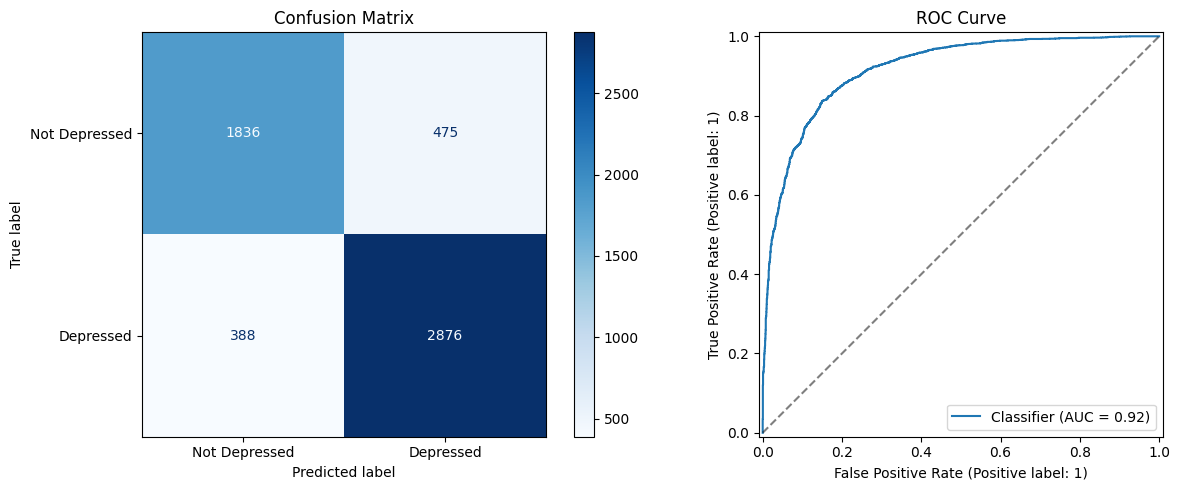

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Not Depressed', 'Depressed'], cmap='Blues', ax=axes[0]
)
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_title('ROC Curve')

plt.tight_layout()
plt.show()

The confusion matrix shows that the model correctly classifies the majority of both classes. In particular, 2875 depressed students and 1836 non-depressed students are correctly identified.
There are 389 false negatives (depressed predicted as not depressed) and 475 false positives. The relatively low number of false negatives is especially important in a mental health context, where failing to identify a depressed student may be more critical than raising a false alarm.
The higher number of depressed cases in the matrix is consistent with the underlying class distribution (59% depressed vs. 41% not depressed). Therefore, the absolute counts reflect the dataset imbalance rather than an inherent bias of the model toward one class.

## 7. Bias-Variance Analysis

I plot the learning curve and the validation curve to analyze the bias/variance trade-off of the selected model.

### 7.1 Learning Curve

The learning curve shows how training and validation F1 change as the training set grows. If both curves converge at a high value, the model has low bias and low variance.

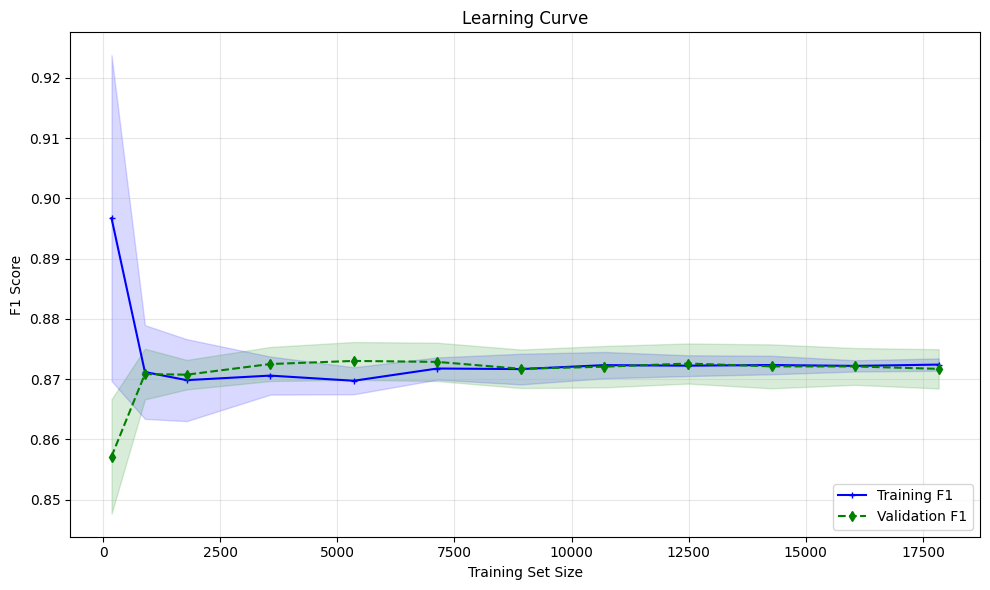

In [ ]:
cls = rs_best.best_estimator_

train_sizes, train_scores, test_scores = learning_curve(
    cls, X=X_train, y=y_train,
    train_sizes=[0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    cv=5, n_jobs=-1, scoring='f1', shuffle=True, random_state=42
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(train_sizes, train_mean, color='blue', marker='+', markersize=5, label='Training F1')
ax.fill_between(train_sizes, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')
ax.plot(train_sizes, test_mean, color='green', linestyle='--', marker='d', markersize=5, label='Validation F1')
ax.fill_between(train_sizes, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')
ax.set_xlabel('Training Set Size')
ax.set_ylabel('F1 Score')
ax.set_title('Learning Curve')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The learning curves show that training and validation F1 quickly converge and remain very close as the training size increases. This suggests low variance and good generalization, with no clear signs of overfitting.

### 7.2 Validation Curve

I look at how F1 changes as a function of `C`. Low `C` means strong regularization (high bias); high `C` means weak regularization (risk of high variance).

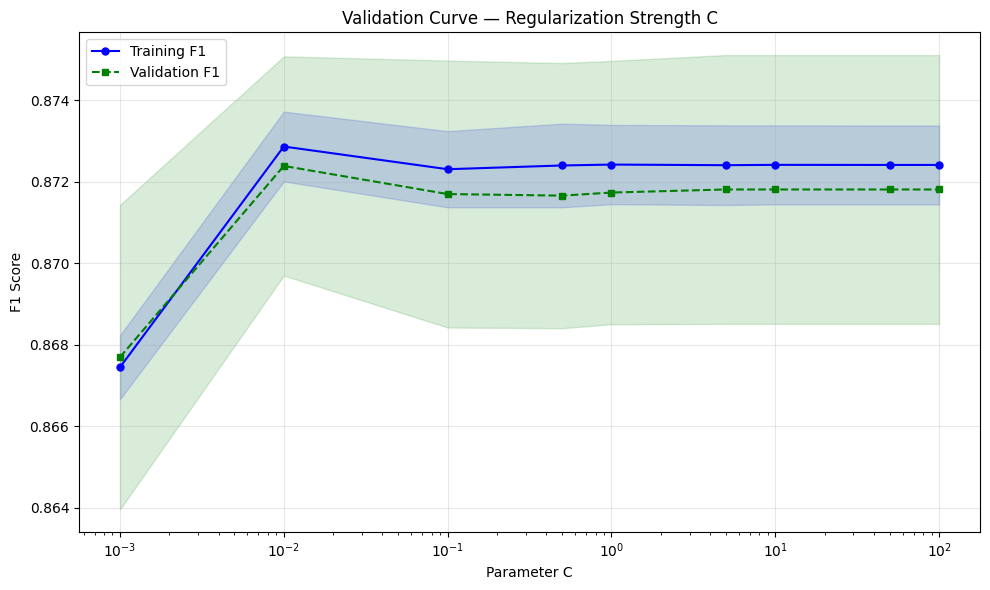

In [ ]:
range_C = [0.001, 0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
train_scores_vc, test_scores_vc = validation_curve(
    cls, X=X_train, y=y_train,
    param_name='classifier__C',
    param_range=range_C,
    cv=5, n_jobs=-1, scoring='f1'
)

train_mean_vc = np.mean(train_scores_vc, axis=1)
train_std_vc = np.std(train_scores_vc, axis=1)
test_mean_vc = np.mean(test_scores_vc, axis=1)
test_std_vc = np.std(test_scores_vc, axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range_C, train_mean_vc, color='blue', marker='o', markersize=5, label='Training F1')
ax.fill_between(range_C, train_mean_vc + train_std_vc, train_mean_vc - train_std_vc, alpha=0.15, color='blue')
ax.plot(range_C, test_mean_vc, color='green', linestyle='--', marker='s', markersize=5, label='Validation F1')
ax.fill_between(range_C, test_mean_vc + test_std_vc, test_mean_vc - test_std_vc, alpha=0.15, color='green')
ax.set_xscale('log')
ax.set_xlabel('Parameter C')
ax.set_ylabel('F1 Score')
ax.set_title('Validation Curve \u2014 Regularization Strength C')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The validation curve shows that performance stabilizes for C ≥ 0.01, with training and validation F1 remaining very close. This indicates that the model is not highly sensitive to the exact choice of regularization strength and does not exhibit strong overfitting.

## 8. Feature Importance

I use two methods:

1. **Coefficient magnitude** — the absolute value of the Logistic Regression coefficients. Since all features are standardized, coefficients are directly comparable and reflect the strength of association with the log-odds of depression.
2. **Permutation importance** — measures the drop in F1-score when a feature is randomly shuffled. This approach is model-agnostic and evaluates the actual contribution of each variable to predictive performance.

Coefficient-based importance reflects how strongly each feature contributes to the model's decision function, while permutation importance measures the impact of each variable on overall performance. Using both methods provides a more robust interpretation, as consistent results increase confidence in the identified key predictors.

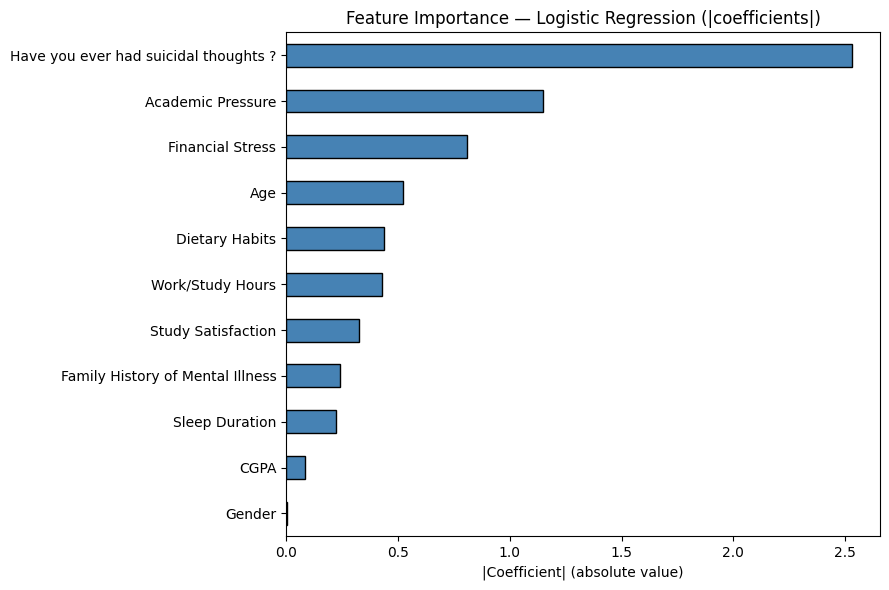

In [ ]:
feature_names = best_clf.named_steps['trans'].get_feature_names_out()
feature_names = [f.split('__')[-1] for f in feature_names]

# Coefficient magnitude
coefs = best_clf.named_steps['classifier'].coef_[0]
feat_imp = pd.Series(np.abs(coefs), index=feature_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
feat_imp.plot(kind='barh', ax=ax, color='steelblue', edgecolor='black')
ax.set_xlabel('|Coefficient| (absolute value)')
ax.set_title('Feature Importance \u2014 Logistic Regression (|coefficients|)')
plt.tight_layout()
plt.show()

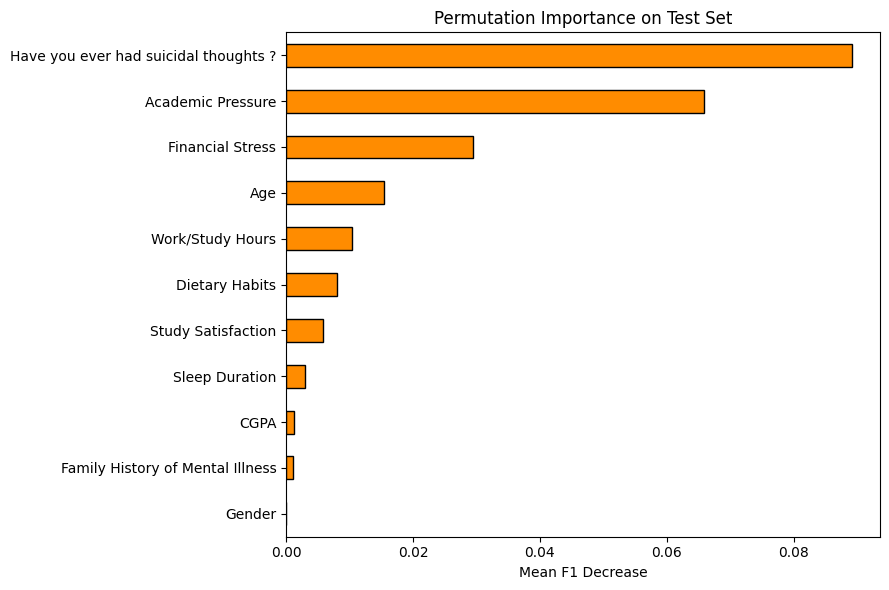

In [ ]:
# Permutation importance on the test set
X_test_transformed = best_clf.named_steps['trans'].transform(X_test)

perm_imp = permutation_importance(
    best_clf.named_steps['classifier'], X_test_transformed, y_test,
    n_repeats=20, random_state=42, scoring='f1', n_jobs=-1
)

perm_series = pd.Series(perm_imp.importances_mean, index=feature_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
perm_series.plot(kind='barh', ax=ax, color='darkorange', edgecolor='black')
ax.set_xlabel('Mean F1 Decrease')
ax.set_title('Permutation Importance on Test Set')
plt.tight_layout()
plt.show()

In [ ]:
print("Top 5 most important features (permutation importance):")
print()
top_5 = perm_series.tail(5).sort_values(ascending=False)
for i, (feat, imp) in enumerate(top_5.items(), 1):
    print(f"  {i}. {feat}: {imp:.4f}")

Top 5 most important features (permutation importance):

  1. Have you ever had suicidal thoughts ?: 0.0891
  2. Academic Pressure: 0.0658
  3. Financial Stress: 0.0294
  4. Age: 0.0155
  5. Work/Study Hours: 0.0104


**Important interpretation note**

The feature importance results presented above highlight variables that are strongly associated with depression within this dataset. However, these findings should not be interpreted as evidence of causal relationships. Since the data are observational and cross-sectional, the model identifies statistical associations rather than direct causal effects. Therefore, while factors such as academic pressure and financial stress are strongly linked to depression in this analysis, no claim of causation can be made.

In [ ]:
print("Depression rate by Suicidal Thoughts")
print(df.groupby('Have you ever had suicidal thoughts ?')['Depression'].mean().round(2))

print("\nDepression rate by Academic Pressure")
print(df.groupby('Academic Pressure')['Depression'].mean().round(2))

print("\nDepression rate by Financial Stress")
print(df.groupby('Financial Stress')['Depression'].mean().round(2))

print("\nDepression rate by Gender")
print(df.groupby('Gender')['Depression'].mean().round(2))

Depression rate by Suicidal Thoughts
Have you ever had suicidal thoughts ?
No     0.23
Yes    0.79
Name: Depression, dtype: float64

Depression rate by Academic Pressure
Academic Pressure
0.0    0.44
1.0    0.19
2.0    0.37
3.0    0.60
4.0    0.76
5.0    0.86
Name: Depression, dtype: float64

Depression rate by Financial Stress
Financial Stress
1.0    0.32
2.0    0.43
3.0    0.59
4.0    0.69
5.0    0.81
Name: Depression, dtype: float64

Depression rate by Gender
Gender
Female    0.58
Male      0.59
Name: Depression, dtype: float64


The descriptive statistics confirm the strong associations identified by the model. In particular, depression rates increase substantially with higher levels of academic pressure and financial stress, and are markedly higher among students who report suicidal thoughts.

## 9. Conclusions

### Model Selection

XGBoost and Logistic Regression achieved nearly identical performance during nested CV (mean outer F1: ~0.87). Despite XGBoost being selected in 3 out of 5 outer folds, Logistic Regression matched or slightly exceeded its test set performance. This tells us that the relationships in this dataset are mostly linear, and a simpler, more interpretable model is sufficient.

### Bias-Variance Analysis

The learning curve shows that training and validation F1 converge quickly and stay close to each other at ~0.87. This means low bias and low variance, the model generalizes well. The validation curve confirms that the model is robust to the choice of `C`: after `C` ≈ 0.1, both curves plateau.

The small gap in the learning curve is largely explained by the presence of "Have you ever had suicidal thoughts?", a very strong binary predictor that allows the model to learn the pattern with very few samples. This is discussed further below.

### Feature Importance

Both methods agree on the ranking. The top features are:

1. **Suicidal thoughts**: by far the strongest predictor. 79% of students who answered "Yes" are depressed, vs only 23% of those who answered "No".
2. **Academic Pressure**: strongest modifiable factor. Depression rate goes from 19% at level 1 to 86% at level 5. Level 0 shows a 44% rate, likely representing missing or non-applicable values rather than a meaningful pressure level.
3. **Financial Stress**: depression rate goes from 32% (level 1) to 81% (level 5).
4. **Dietary Habits** and **Sleep Duration**: unhealthy eating and short sleep are associated with higher depression.
5. **Gender**: near-zero importance. Depression rates are almost identical for males and females, confirming our choice to let the model decide rather than dropping it beforehand.

### Note on "Have you ever had suicidal thoughts?"

This feature is the strongest predictor, but it is important to note that suicidal ideation is a **symptom** of depression, not an independent cause. Including it makes the prediction somewhat circular. The remaining top features (Academic Pressure, Financial Stress, Sleep, Diet) are the truly actionable risk factors that could be used for prevention strategies at the university level.

### Limitations

The dataset is cross-sectional, so we cannot establish causality from these associations.